linear regression assume the outputs to be the value when the input is put in a linear function

e.g f(x) = w1*x1 + w2*x2 +....+ wn*xn +b

where wn is the nth weight or suitable coffeient for the best linear function

xn is the input data

b is the bias or y intercept when input is in x coordinate




---
one more thing not just linear line but we can map curve also with a technique called polynomial input we map x as x^2 or any other possible plynomial fuction we will see that later in the notebook so lets begin



**We start by first importing pandas for data structing and matplotlib for data visualization**

In [ ]:
!pip install matplotlib pandas

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
# i do not have any data set so we create our own
import numpy as np

x = np.arange(20,300,5)

y =9*x+5 # we got the eqn but lets pretend we dont

In [ ]:
# Create the DataFrame
df = pd.DataFrame({'x': x, 'y': y})

# View the first 5 rows
print(df.head())

    x    y
0  20  185
1  25  230
2  30  275
3  35  320
4  40  365


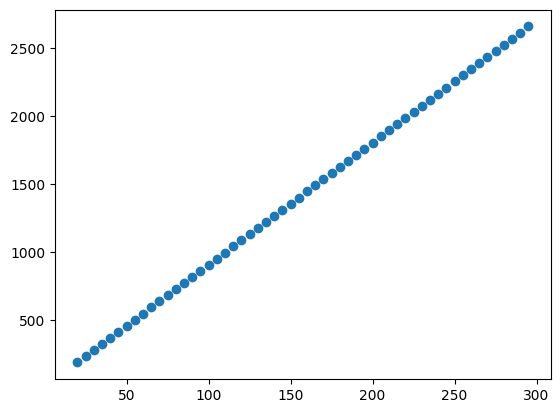

In [ ]:
plt.scatter(df.x,df.y) # create a scatter ,plot see how it is linear ,

plt.show()

lets create a loss function as to find how accurate our model is

In [ ]:
def loss(prediction,dataset):
  total_error=0 # start from 0 error
  m = len(prediction)
  for i in range(m):
    total_error += abs(prediction[i]-dataset[i])**2 # use abs to make all the loss positive so no one cancel each other

  return total_error/m
# if u want only the error


In [ ]:
def compute_cost(w, b, data):
    total_error = 0
    m = len(data)

    for i in range(m):
        x = data.iloc[i,0]
        y = data.iloc[i,1]
        # 1. Make a fresh prediction using the current w and b
        prediction = w * x + b

        # 2. Calculate the squared error against the actual value (y)
        total_error += (prediction - y) ** 2

    # Dividing by 2*m is standard in gradient descent to make the calculus cleaner later
    return total_error / (2 * m)



In [ ]:
print(compute_cost(9,5,df))

0.0


lets build gradient descent

Stochastic Gradient Descent

Batch vs. Stochastic Gradient Descent


Feature	Update Outside Loop (Batch GD)	Update Inside Loop (Stochastic GD)
Update frequency	Once per full pass over the data.	Once per individual data point (\(n\) times per pass).
Path to minimum	Smooth, steady, and predictable.	Noisy and zig-zagging, because individual outliers pull w and b around.
Speed on large data	Slow to start, since it must read all rows before making one update.	Very fast updates, making it ideal for massive datasets.


In [13]:
def gradient_descent(w,b,data,a):
  wf =0
  bf =0
  n = len(data)
  for i in range(n):

     x = data.iloc[i,0]
     y = data.iloc[i,1]
     f = w*x+b
     wf += (1/n)*x*(f-y)
     bf += (1/n)*(f-y)
     w = w - a * wf
     b = b - a * bf

  return w,b




In [10]:
print(gradient_descent(1,2,df,0.01))

(np.float64(-9.61785847378574e+20), np.float64(-3.2525669328675876e+18))



Why Updating Outside the Loop Works (Batch Gradient Descent)

• True average direction: Each data point \((x, y)\) pulls the line in a slightly different direction. By summing the gradients across all \(n\) points first, you find the exact average downhill slope for the entire dataset before taking a single, steady step.
• Outer training loop: A single call to gradient_descent() only performs one step. To actually train the model, you wrap that entire function inside an outer loop (called epochs) that runs hundreds or thousands of times until w and b settle on the best fit.


In [ ]:
def gradient_descent(w, b, data, a):
    wf = 0
    bf = 0
    n = len(data)

    for i in range(n):
        x = data.iloc[i, 0]
        y = data.iloc[i, 1]
        f = w * x + b

        # Calculate gradients (note: (f - y) already accounts for the negative sign)
        wf += (1/n) * x * (f - y)
        bf += (1/n) * (f - y)

    # Update weights and bias
    w = w - a * wf
    b = b - a * bf

    return w, b


In [11]:
print(gradient_descent(1,2,df,0.01))

(np.float64(-9.61785847378574e+20), np.float64(-3.2525669328675876e+18))


now linear regession time baby

In [15]:
w = float(input("enter your initial weight assumption "))
b = float(input("enter your initial baises assumption "))
a = float(input("enter your learning rate "))
epochs = int(input("enter no of epochs u want assumption "))

for i in range(epochs):
  w,b = gradient_descent(w,b,df,a)

print(f"the eqn is {w}x+{b}")

enter your initial weight assumption 6
enter your initial baises assumption 6
enter your learning rate 0.001
enter no of epochs u want assumption 200
the eqn is 8.992024324412009x+6.001235429140717


In [17]:
print(y[1:10])
z = 8.992024324412009*x+6.001235429140717
print(z[1:10])

[230 275 320 365 410 455 500 545 590]
[230.80184354 275.76196516 320.72208678 365.68220841 410.64233003
 455.60245165 500.56257327 545.52269489 590.48281652]


see so similar the result lets go for epoch

In [18]:
w = float(input("enter your initial weight assumption "))
b = float(input("enter your initial baises assumption "))
a = float(input("enter your learning rate "))
epochs = int(input("enter no of epochs u want assumption "))

for i in range(epochs):
  w,b = gradient_descent(w,b,df,a)

print(f"the eqn is {w}x+{b}")
print(y[1:10])
z = 8.992024324412009*x+6.001235429140717
print(z[1:10])

enter your initial weight assumption 6
enter your initial baises assumption 6
enter your learning rate 0.001
enter no of epochs u want assumption 500
the eqn is 8.995306661139168x+5.589183586592255
[230 275 320 365 410 455 500 545 590]
[230.80184354 275.76196516 320.72208678 365.68220841 410.64233003
 455.60245165 500.56257327 545.52269489 590.48281652]


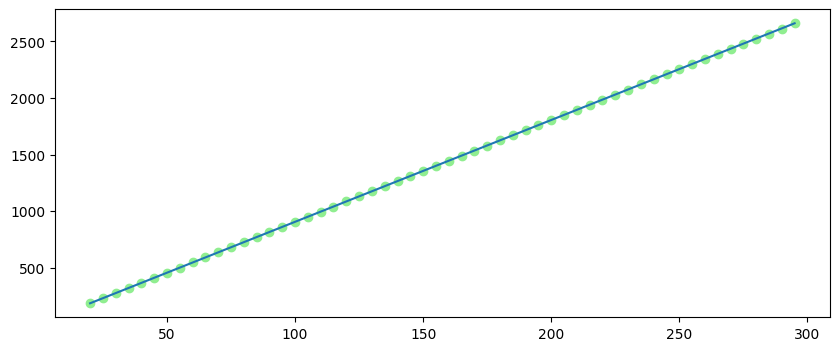

In [20]:
import matplotlib.pyplot as plt
fig,ax= plt.subplots(figsize =(10,4))
ax.scatter(x,z,color ="lightgreen")
ax.plot(x,y)

plt.show()
